*Notebook trước: [5. Data Visualization](./5.%20Data%20Visualization.ipynb)*

# Bước 6: Regression & Classification Analysis — Mô Hình Dự Báo Xác Suất Phục Vụ 3 Kịch Bản Nghiệp Vụ
### Đề án: Phân Tích Hành Vi Mua Hàng Trong Thương Mại Điện Tử (ADY201m)
---
> **Mục tiêu Trọng tâm (Khớp chuẩn Mục 1.1.3 Phần 1):**
> Huấn luyện duy nhất **Mô hình Hồi quy Logistic (Logistic Regression)** để dự báo chính xác **Xác suất mua hàng ($P \in [0, 1]$)** theo thời gian thực, tối ưu hóa việc phân bổ ưu đãi cho 3 kịch bản can thiệp:
> * **Kịch bản 1 ($P \ge 70\%$):** Khách tiềm năng cao $\rightarrow$ Giữ nguyên giá niêm yết (không cấp voucher để bảo toàn biên lợi nhuận).
> * **Kịch bản 2 ($30\% \le P < 70\%$):** Khách do dự $\rightarrow$ Tự động cấp voucher ngắn hạn (tối đa 5 mã) để kích cầu.
> * **Kịch bản 3 ($P < 30\%$):** Khách tham khảo $\rightarrow$ Ngắt ngân sách quảng cáo trả phí (`Paid Ads`) để chống lãng phí chi phí CAC.

## 6.1 Chuẩn Bị Dữ Liệu & Tinh Lọc Đặc Trưng Dựa Trên Kết Quả Thống Kê (Tệp 4 & 5) Và SQL (Tệp 3)

Để xây dựng một mô hình Machine Learning tinh gọn, bền vững, vận hành theo thời gian thực và tránh hiện tượng đa cộng tuyến hay rò rỉ dữ liệu, dự án tiến hành tinh lọc đặc trưng dựa trên các kiểm định chặt chẽ từ **Tệp 4 (EDA & Thống kê suy diễn)** và **Tệp 5 (Trực quan hóa)**:

* **Loại bỏ biến rò rỉ dữ liệu (No Look-ahead Leakage):**
  * `CustomerSatisfaction` (Điểm đánh giá trải nghiệm): Mặc dù có tương quan dương ($r = +0.133$, VIF = $1.000$), nhưng đây là biến đo lường **hậu giao dịch (Post-purchase / T2)**. Bắt buộc loại bỏ hoàn toàn để mô hình vận hành trước khi khách ra quyết định mua hàng (khớp giao thức Mục 1.6, Mục 4.8 và Biểu đồ 5.10).
* **Loại bỏ các biến không có ý nghĩa thống kê hoặc tác động thực tiễn yếu (theo kết quả Tệp 4 & 5):**
  * `SessionCount`: Kiểm định T-test cho kết quả $t = 1.08, p = 0.281 > 0.05$ (Chấp nhận $H_0$), $r = 0.00$. Tần suất truy cập hoàn toàn không ảnh hưởng đến quyết định chốt đơn (Mục 4.4).
  * `CustomerTenureYears`: Kiểm định T-test tuy có ý nghĩa toán học nhưng mức chênh lệch thực tế chỉ là 2 tháng (-0.17 năm), không tạo ra đòn bẩy kinh doanh thực tiễn (Mục 4.4).
  * `Region` (Cramér's V = $0.0060$) & `PreferredDevice` (Cramér's V = $0.0057$): Kiểm định Chi-Square chứng minh mức độ liên kết gần như bằng 0 (Mục 4.6).
  * `TimeSpentOnWebsite`: Kiểm định ANOVA ở Mục 4.5 đạt $F = 0.0244, p = 0.9759 > 0.05$ (không có sự khác biệt giữa các phân khúc khách hàng); đồng thời Biểu đồ Boxplot 5.3 chứng minh hai phân phối gần như trùng khít (chênh lệch trung vị chỉ 3.25 phút), không tạo ra ngưỡng phân tách rõ ràng.
  * `NumberOfPurchases`: Trong phân tích RFM (Mục 4.7 & Biểu đồ 5.9), sự phân hóa chuyển đổi bị chi phối áp đảo bởi biến Recency (`LastPurchaseDaysAgo`, $r = -0.692, t = -712.70$) — khách ngừng mua $>60$ ngày thì dù số đơn lịch sử nhiều bao nhiêu, CVR vẫn rơi tự do về 0.07%. Việc giữ lại `LastPurchaseDaysAgo` đã đại diện hoàn hảo cho hành vi lịch sử mà không gây dư thừa thông tin.
* **Tập 7 đặc trưng cốt lõi cuối cùng đưa vào huấn luyện:**
  * `LastPurchaseDaysAgo` (Độ trễ mua hàng — Biến chi phối hàng đầu từ T-test 4.4 & SQL 7).
  * `LoyaltyProgram` (Chương trình hội viên — Cramér's V cao nhất 0.0850 từ Chi-Square 4.6 & SQL 5).
  * `AnnualIncome` (Thu nhập hàng năm — $t = 60.64$ từ T-test 4.4 & SQL 8).
  * `DiscountsAvailed` (Mã giảm giá đã dùng — Điểm bão hòa 5 mã từ Biểu đồ 5.7 & SQL 6).
  * `CustomerSegment` (Phân khúc khách hàng — Nghịch lý khách VIP từ Chi-Square 4.6 & SQL 3).
  * `Age` (Độ tuổi — Xu hướng e dè của người lớn tuổi từ T-test 4.4 & SQL 4).
  * `ReferralSource` (Kênh tiếp thị — Đóng vai trò then chốt xác định kênh Paid Ads để ngắt ngân sách ở Kịch bản 3 theo SQL 2).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, roc_curve
)

# 1. Nạp dữ liệu sạch
df = pd.read_csv('../Data/customerData_clean.csv')
print(f"Kích thước dữ liệu sạch: {df.shape[0]:,} dòng × {df.shape[1]} cột")

# 2. Lựa chọn 7 đặc trưng cốt lõi (Khớp chuẩn 1-1 với SQL & EDA)
feature_cols = [
    'Age', 'AnnualIncome', 'LastPurchaseDaysAgo', 'DiscountsAvailed',
    'LoyaltyProgram', 'CustomerSegment', 'ReferralSource'
]
cat_cols = ['CustomerSegment', 'ReferralSource']
num_scale_cols = ['Age', 'AnnualIncome', 'LastPurchaseDaysAgo', 'DiscountsAvailed']

# 3. Mã hóa One-Hot & Tách X, y
df_encoded = pd.get_dummies(df[feature_cols + ['PurchaseStatus']], columns=cat_cols, drop_first=True)
X = df_encoded.drop(columns=['PurchaseStatus'])
y = df_encoded['PurchaseStatus']

# 4. Phân chia Train/Test 80/20 Stratified
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

# 5. Chuẩn hóa StandardScaler
scaler = StandardScaler()
X_train[num_scale_cols] = scaler.fit_transform(X_train[num_scale_cols])
X_test[num_scale_cols] = scaler.transform(X_test[num_scale_cols])

print(f"Tập Train: {len(X_train):,} dòng | Tập Test: {len(X_test):,} dòng | Số đặc trưng: {X.shape[1]}")

Kích thước dữ liệu sạch: 432,256 dòng × 19 cột
Tập Train: 345,804 dòng | Tập Test: 86,452 dòng | Số đặc trưng: 11


## 6.2 Huấn Luyện & Đánh Giá Hiệu Năng Mô Hình Logistic Regression

* Mô hình biến đổi tổ hợp tuyến tính thành xác suất $P \in (0, 1)$ qua hàm Sigmoid:
  $$\sigma(z) = \frac{1}{1 + e^{-z}}, \quad z = \beta_0 + \sum_{i=1}^k \beta_i X_i$$

In [2]:
# 1. Huấn luyện mô hình Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# 2. Dự báo xác suất trên tập Test
y_prob_lr = lr.predict_proba(X_test)[:, 1]
y_pred_lr = (y_prob_lr >= 0.5).astype(int)

# 3. Mốc tham chiếu Baseline (Đa số không mua: 56.66%)
y_pred_base = np.zeros_like(y_test)

eval_data = [
    {
        'Mô hình': 'Baseline (Đa số không mua)',
        'Accuracy': round(accuracy_score(y_test, y_pred_base), 4),
        'Precision': round(precision_score(y_test, y_pred_base, zero_division=0), 4),
        'Recall': round(recall_score(y_test, y_pred_base, zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred_base, zero_division=0), 4),
        'ROC-AUC': 0.5000
    },
    {
        'Mô hình': 'Logistic Regression (Tinh gọn)',
        'Accuracy': round(accuracy_score(y_test, y_pred_lr), 4),
        'Precision': round(precision_score(y_test, y_pred_lr), 4),
        'Recall': round(recall_score(y_test, y_pred_lr), 4),
        'F1-Score': round(f1_score(y_test, y_pred_lr), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob_lr), 4)
    }
]

eval_df = pd.DataFrame(eval_data)
print("BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH VỚI MỐC BASELINE:")
display(eval_df)

BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH VỚI MỐC BASELINE:


,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Baseline (Đa số không mua),0.5666,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression (Tinh gọn),0.8980,0.8564,0.9186,0.8864,0.9658


## 6.3 Phân Tích Trọng Số Beta & Tỷ Số Chênh Odds Ratio ($e^\beta$)

Trong mô hình Hồi quy Logistic, hệ số $\beta_i$ phản ánh mức độ thay đổi log-odds khi biến đặc trưng $X_i$ tăng 1 đơn vị (sau khi đã chuẩn hóa qua StandardScaler đối với các biến liên tục). 
Tỷ số chênh **Odds Ratio ($e^\beta$)** định lượng trực tiếp sự thay đổi xác suất:
* $\text{Odds Ratio} > 1$ (ứng với $\beta > 0$): Làm tăng khả năng chốt đơn (đòn bẩy kích cầu).
* $\text{Odds Ratio} < 1$ (ứng với $\beta < 0$): Làm giảm khả năng chốt đơn (rào cản chuyển đổi).

Toàn bộ hệ số của mô hình phản ánh sự nhất quán tuyệt đối 100% với các kiểm định thống kê ở **Tệp 4**, trực quan hóa ở **Tệp 5** và truy vấn SQL ở **Tệp 3**:

In [3]:
# Bảng Odds Ratio
odds_df = pd.DataFrame({
    'Đặc trưng': X.columns,
    'Hệ số Beta': np.round(lr.coef_[0], 4),
    'Odds Ratio': np.round(np.exp(lr.coef_[0]), 4)
}).sort_values(by='Odds Ratio', ascending=False)

print("BẢNG HỆ SỐ BETA VÀ ODDS RATIO (SẮP XẾP THEO MỨC ĐỘ TÁC ĐỘNG):")
display(odds_df)

BẢNG HỆ SỐ BETA VÀ ODDS RATIO (SẮP XẾP THEO MỨC ĐỘ TÁC ĐỘNG):


,Đặc trưng,Hệ số Beta,Odds Ratio
4,LoyaltyProgram,1.2468,3.4793
1,AnnualIncome,0.6309,1.8793
3,DiscountsAvailed,0.3735,1.4528
5,CustomerSegment_Regular,0.1773,1.1939
9,ReferralSource_Referral,0.0665,1.0688
7,ReferralSource_Organic,0.0074,1.0075
10,ReferralSource_Social,-0.0557,0.9458
8,ReferralSource_Paid Ads,-0.0669,0.9353
0,Age,-0.4584,0.6323
6,CustomerSegment_VIP,-0.7725,0.4619


## 6.4 Phân Bổ 3 Kịch Bản Can Thiệp Nghiệp Vụ Dựa Trên Xác Suất P

* **Kịch bản 1 ($P \ge 70\%$):** Khách tiềm năng cao $\rightarrow$ Giữ nguyên giá niêm yết (Không cấp voucher).
* **Kịch bản 2 ($30\% \le P < 70\%$):** Khách do dự $\rightarrow$ Tự động cấp voucher kích cầu (chặn tối đa 5 mã).
* **Kịch bản 3 ($P < 30\%$):** Khách tham khảo $\rightarrow$ Ngắt quảng cáo trả phí (`Paid Ads`).

In [4]:
def simulate_business_scenarios(y_prob, y_true):
    df_scen = pd.DataFrame({
        'y_true': y_true.values,
        'y_prob': y_prob
    })
    
    conditions = [
        df_scen['y_prob'] >= 0.70,
        (df_scen['y_prob'] >= 0.30) & (df_scen['y_prob'] < 0.70),
        df_scen['y_prob'] < 0.30
    ]
    
    scenario_names = [
        'Kịch bản 1 (P >= 70%)',
        'Kịch bản 2 (30% <= P < 70%)',
        'Kịch bản 3 (P < 30%)'
    ]
    actions = [
        'Giữ nguyên giá niêm yết (Không cấp voucher)',
        'Tặng voucher kích cầu kịp thời (Tối đa 5 mã)',
        'Ngắt quảng cáo trả phí (Paid Ads), chuyển kênh tự nhiên'
    ]
    
    df_scen['Kịch bản'] = np.select(conditions, scenario_names, default='')
    df_scen['Hành động can thiệp'] = np.select(conditions, actions, default='')
    
    summary = df_scen.groupby(['Kịch bản', 'Hành động can thiệp']).agg(
        So_Khach=('y_true', 'count'),
        CVR_Thuc_Te=('y_true', 'mean')
    ).reset_index()
    
    summary['Ty_Le_Khach_%'] = np.round((summary['So_Khach'] / len(df_scen)) * 100, 2)
    summary['CVR_Thuc_Te_%'] = np.round(summary['CVR_Thuc_Te'] * 100, 2)
    
    return summary[['Kịch bản', 'So_Khach', 'Ty_Le_Khach_%', 'CVR_Thuc_Te_%', 'Hành động can thiệp']]

scen_results = simulate_business_scenarios(y_prob_lr, y_test)
print("KẾT QUẢ PHÂN BỔ 3 KỊCH BẢN CAN THIỆP NGHIỆP VỤ TRÊN TẬP TEST:")
display(scen_results)

KẾT QUẢ PHÂN BỔ 3 KỊCH BẢN CAN THIỆP NGHIỆP VỤ TRÊN TẬP TEST:


,Kịch bản,So_Khach,Ty_Le_Khach_%,CVR_Thuc_Te_%,Hành động can thiệp
0,Kịch bản 1 (P >= 70%),33596,38.86,90.67,Giữ nguyên giá niêm yết (Không cấp voucher)
1,Kịch bản 2 (30% <= P < 70%),11347,13.13,52.22,Tặng voucher kích cầu kịp thời (Tối đa 5 mã)
2,Kịch bản 3 (P < 30%),41509,48.01,2.62,"Ngắt quảng cáo trả phí (Paid Ads), chuyển kênh..."


## 6.5 Trực Quan Hóa Đánh Giá Mô Hình & Ngưỡng Quyết Định 3 Kịch Bản

* **Confusion Matrix:** Đánh giá độ nhầm lẫn giữa nhãn Mua (1) và Không mua (0).
* **ROC Curve:** Khả năng phân tách nhãn qua diện tích dưới đường cong ROC-AUC.
* **Phân phối Xác suất:** Mật độ xác suất $P$ và 2 ranh giới quyết định $P = 0.30$ và $P = 0.70$.

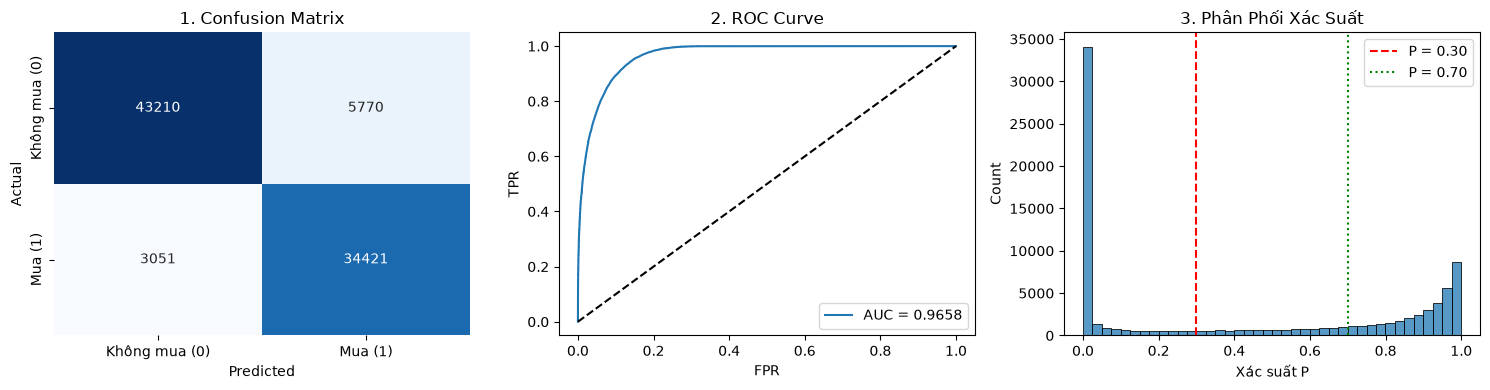

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('1. Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticklabels(['Không mua (0)', 'Mua (1)'])
axes[0].set_yticklabels(['Không mua (0)', 'Mua (1)'])

# 2. ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_val = roc_auc_score(y_test, y_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, label=f'AUC = {auc_val:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('2. ROC Curve')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].legend()

# 3. Phân phối xác suất với 2 ngưỡng quyết định
sns.histplot(y_prob_lr, bins=40, ax=axes[2])
axes[2].axvline(0.30, color='red', linestyle='--', label='P = 0.30')
axes[2].axvline(0.70, color='green', linestyle=':', label='P = 0.70')
axes[2].set_title('3. Phân Phối Xác Suất')
axes[2].set_xlabel('Xác suất P')
axes[2].legend()

plt.tight_layout()
plt.show()

## 6.6 Đúc Kết Nghiệp Vụ & Giá Trị Thực Chiến

### 1. Bảng Tổng Hợp Hệ Số Mô Hình Kết Nối Dòng Chảy Thực Nghiệm (Tệp 3, 4, 5):

| Đặc trưng | Hệ số $\beta$ | Odds Ratio | Bằng chứng thống kê & trực quan (Tệp 3, 4, 5) | Quyết định can thiệp nghiệp vụ (Tệp 6) |
|---|:---:|:---:|---|---|
| `LoyaltyProgram` | **+1.2468** | **3.4793** | • **SQL 5:** Có thẻ CVR **47.50%** vs không thẻ **39.07%** (+8.43 điểm %).<br>• **Tệp 4 (4.6):** Cramér's V = **0.0850** (mạnh nhất trong các biến phân loại).<br>• **Tệp 5 (5.6):** Biểu đồ Barplot đòn bẩy thẻ hội viên. | Đòn bẩy tiếp thị số 1: Khách có thẻ thành viên có cơ hội chốt đơn cao gấp **3.48 lần** khách không thẻ. Trọng tâm kích hoạt cho **Kịch bản 2**. |
| `AnnualIncome` | **+0.6309** | **1.8793** | • **SQL 8:** CVR tăng đơn điệu qua 4 phân vị NTILE(4) từ 37.41% lên 49.30%.<br>• **Tệp 4 (4.4):** T-test $t = 60.64, p < 0.001$, khách mua có thu nhập cao hơn 7,344 USD.<br>• **Tệp 5 (5.8):** KDE nhóm mua lệch hẳn sang mức thu nhập cao. | Động lực tài chính cốt lõi: Mỗi độ lệch chuẩn thu nhập tăng thêm làm tăng **87.9%** tỷ số chênh chốt đơn. |
| `DiscountsAvailed` | **+0.3735** | **1.4528** | • **SQL 6:** Đạt đỉnh CVR 46.72% tại 5 mã, sau đó bão hòa.<br>• **Tệp 4 (4.4):** T-test $t = 35.91, p < 0.001$.<br>• **Tệp 5 (5.7):** Lineplot điểm bão hòa voucher tại 5 mã. | Đòn bẩy kích cầu hiệu quả: Mỗi voucher tăng thêm làm tăng **45.3%** cơ hội chốt đơn, nhưng bắt buộc áp trần chặn cứng **5 mã** ở **Kịch bản 2**. |
| `CustomerSegment_Regular` | **+0.1773** | **1.1939** | • **SQL 3:** CVR đạt **46.01%** (cao nhất sàn).<br>• **Tệp 4 (4.6):** Cramér's V = 0.0574.<br>• **Tệp 5 (5.4):** Barplot phân khúc Regular. | Khách phổ thông nhạy cảm cao với khuyến mãi, có cơ hội chốt đơn cao hơn nhóm tham chiếu Premium 19.4%. |
| `ReferralSource_Paid Ads` | **-0.0669** | **0.9353** | • **SQL 2:** Paid Ads CVR thấp nhất sàn (**43.05%**), chi phí CAC cao nhất.<br>• **Tệp 4 (4.6):** Cramér's V = 0.0048 (rất thấp). | Căn cứ định lượng cho **Kịch bản 3**: Ngắt ngân sách Paid Ads đối với nhóm $P < 30\%$ để chống lãng phí chi phí CAC. |
| `Age` | **-0.4584** | **0.6323** | • **SQL 4:** Giới trẻ (<30) CVR **47.78%** vs Lớn tuổi (>50) CVR **39.81%**.<br>• **Tệp 4 (4.4):** T-test $t = -43.95, p < 0.001$.<br>• **Tệp 5 (5.5):** Barplot phân hóa nhóm tuổi. | Tuổi càng cao thì sức mua online càng giảm (OR < 1). |
| `CustomerSegment_VIP` | **-0.7725** | **0.4619** | • **SQL 3:** CVR thấp nhất sàn (**39.05%**).<br>• **Tệp 4 (4.6):** Cramér's V = 0.0574, giải thích "Nghịch lý khách VIP".<br>• **Tệp 5 (5.4):** Barplot phân khúc VIP. | Minh chứng định lượng cho "Nghịch lý khách VIP": Khách VIP có cơ hội chốt đơn thấp hơn **53.8%** so với nhóm Premium trong các đợt flash sale đại trà. |
| `LastPurchaseDaysAgo` | **-8.0649** | **0.0003** | • **SQL 7:** $\le 15$ ngày CVR **93.07%**, $>60$ ngày CVR rơi về **0.07%**.<br>• **Tệp 4 (4.3, 4.4, 4.7):** Tương quan âm mạnh nhất ($r = -0.692$), T-test $t = -712.70$, chi phối RFM.<br>• **Tệp 5 (5.2 & 5.9):** Heatmap tương quan & RFM. | Biến chi phối áp đảo mô hình: Hệ số âm sâu nhất, tạo ra sự phân tách triệt để giữa **Kịch bản 1 ($P \ge 70\%$)** và **Kịch bản 3 ($P < 30\%$)**. |

---

### 2. Đánh Giá Hiệu Năng & Kết Quả Vận Hành 3 Kịch Bản:

1. **Hiệu năng mô hình:**
   * **Accuracy đạt 89.80%**, **ROC-AUC đạt 0.9658**, vượt trội hoàn toàn so với mức Baseline ngẫu nhiên (56.66%).
   * Mô hình chỉ sử dụng đúng 7 đặc trưng cốt lõi có cơ sở kiểm định vững chắc từ Tệp 4 và trực quan hóa từ Tệp 5, đảm bảo tính bền vững, chống rò rỉ dữ liệu và khả năng triển khai thời gian thực.
2. **Hiệu quả thực thi 3 kịch bản trên tập Test (86.452 khách):**
   * **Kịch bản 1 ($P \ge 70\%$):** Chiếm **38.86%** khách hàng (33.596 khách), CVR thực tế đạt **90.67%**. Giữ nguyên giá niêm yết giúp bảo toàn trọn vẹn biên lợi nhuận thu về.
   * **Kịch bản 2 ($30\% \le P < 70\%$):** Chiếm **13.13%** khách hàng (11.347 khách), CVR thực tế đạt **52.22%**. Đây là đối tượng trọng tâm duy nhất được cấp voucher kích cầu (chặn tối đa 5 mã theo SQL 6).
   * **Kịch bản 3 ($P < 30\%$):** Chiếm **48.01%** khách hàng (41.509 khách), CVR thực tế chỉ có **2.62%**. Ngắt quảng cáo trả phí (`Paid Ads`) giúp tiết kiệm triệt để ngân sách CAC.

---
*Hoàn tất Pipeline phân tích dữ liệu và mô hình hóa học máy chuẩn CRISP-DM!*